Compose a graphic of an orange, lemon, and lime.

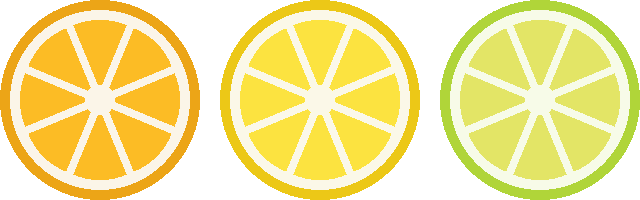


### Citrus Sector

The inside of a sliced citrus fruit is composed of a ring of circular sectors.

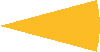

Implement the `citrus_sector` function.
Use <API>circular_sector</API> to create the sector
and use <API>rotate</API> to rotate it so it is centered along the x-axis.

In [ ]:
from pytamaro import Color, hsl_color, Graphic, rotate, circular_sector, show_graphic

# Colors for oranges, lemons, and limes
ORANGE_SKIN_COLOR = hsl_color(40, 0.85, 0.51)
ORANGE_PITH_COLOR = hsl_color(40, 0.75, 0.95)
ORANGE_FLESH_COLOR = hsl_color(42, 0.98, 0.57)
LEMON_SKIN_COLOR = hsl_color(50, 0.85, 0.51)
LEMON_PITH_COLOR = hsl_color(50, 0.75, 0.95)
LEMON_FLESH_COLOR = hsl_color(52, 0.97, 0.62)
LIME_SKIN_COLOR = hsl_color(74, 0.65, 0.53)
LIME_PITH_COLOR = hsl_color(74, 0.75, 0.95)
LIME_FLESH_COLOR = hsl_color(61, 0.71, 0.65)

def citrus_sector(diameter: float, color: Color, angle: float) -> Graphic:
    return #TODO

show_graphic(citrus_sector(200, ORANGE_FLESH_COLOR, 30))

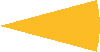

In [1]:
#teacher-only
from pytamaro import Color, hsl_color, Graphic, rotate, circular_sector, show_graphic

# Colors for oranges, lemons, and limes
ORANGE_SKIN_COLOR = hsl_color(40, 0.85, 0.51)
ORANGE_PITH_COLOR = hsl_color(40, 0.75, 0.95)
ORANGE_FLESH_COLOR = hsl_color(42, 0.98, 0.57)
LEMON_SKIN_COLOR = hsl_color(50, 0.85, 0.51)
LEMON_PITH_COLOR = hsl_color(50, 0.75, 0.95)
LEMON_FLESH_COLOR = hsl_color(52, 0.97, 0.62)
LIME_SKIN_COLOR = hsl_color(74, 0.65, 0.53)
LIME_PITH_COLOR = hsl_color(74, 0.75, 0.95)
LIME_FLESH_COLOR = hsl_color(61, 0.71, 0.65)

def citrus_sector(diameter: float, color: Color, angle: float) -> Graphic:
    return rotate(
        -angle / 2,
        circular_sector(diameter / 2, angle, color)
    )

show_graphic(citrus_sector(200, ORANGE_FLESH_COLOR, 30))

### Circle

Create a function `circle` that produces a circle.
Use <API>ellipse</API>.

In [ ]:
from pytamaro import ellipse

def circle(diameter: float, color: Color) -> Graphic:
    return #TODO

show_graphic(circle(100, ORANGE_SKIN_COLOR))

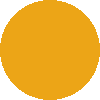

In [2]:
#teacher-only
from pytamaro import ellipse

def circle(diameter: float, color: Color) -> Graphic:
    return ellipse(diameter, diameter, color)

show_graphic(circle(100, ORANGE_SKIN_COLOR))

### Compose multiple graphics into one

Create a function `composes` that takes a list of graphics and composes them into a single graphic.
Use repetition, starting with an <API>empty_graphic</API> and combining graphics with <API>compose</API>.

In [ ]:
from pytamaro import empty_graphic, compose

def composes(graphics: list[Graphic]) -> Graphic:
    result = empty_graphic()
    #TODO
    return result

show_graphic(composes([circle(80, ORANGE_FLESH_COLOR), circle(90, ORANGE_PITH_COLOR), circle(100, ORANGE_SKIN_COLOR)]))

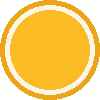

In [8]:
#teacher-only
from pytamaro import empty_graphic, compose

def composes(graphics: list[Graphic]) -> Graphic:
    result = empty_graphic()
    for graphic in graphics:
        result = compose(result, graphic)
    return result

show_graphic(composes([circle(80, ORANGE_FLESH_COLOR), circle(90, ORANGE_PITH_COLOR), circle(100, ORANGE_SKIN_COLOR)]))

### Ring

Create a function `ring` that produces a ring of `count` graphics, evenly spread across the 360 degrees of a circle.
The inside diameter of the ring should correspond to `diameter`
(the citrus segments should form a ring just outside the diameter).

Hint: If you need help, check out the <b>Sliced Pitaya</b> activity.

In [ ]:
from pytamaro import pin, center_left, beside, rectangle, black

def ring(count: int, diameter: float, graphic: Graphic) -> Graphic:
    return #TODO

show_graphic(ring(8, 10, citrus_sector(90, ORANGE_FLESH_COLOR, 45)))

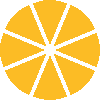

In [12]:
#teacher-only
from pytamaro import pin, center_left, beside, rectangle, black

def ring(count: int, diameter: float, graphic: Graphic) -> Graphic:
    return composes(
        [
            rotate(
                i * 360 / count,
                pin(center_left, beside(rectangle(diameter / 2, 0, black), graphic))
            ) 
            for i in range(count)
        ]
    )

show_graphic(ring(8, 10, citrus_sector(90, ORANGE_FLESH_COLOR, 45)))

### Sliced citrus

Implement a function `sliced_citrus` that composes a sliced citrus from:

* core pith circle - 0.15 * fruit diameter
* ring of citrus sectors - ring diameter of 0.1 * fruit diameter, sector diameter of 0.7 * fruit diameter
* outer pith circle - 0.9 * fruit diameter
* skin circle - 1.0 * fruit diameter

Use your `composes` function.

In [ ]:
def sliced_citrus(diameter: float, skin_color: Color, pith_color: Color, flesh_color: Color) -> Graphic:
    return #TODO

show_graphic(sliced_citrus(200, ORANGE_SKIN_COLOR, ORANGE_PITH_COLOR, ORANGE_FLESH_COLOR))

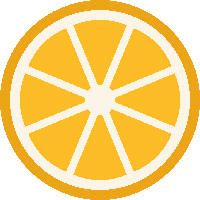

In [15]:
#teacher-only
def sliced_citrus(diameter: float, skin_color: Color, pith_color: Color, flesh_color: Color) -> Graphic:
    return composes([
        circle(diameter * 0.15, pith_color),
        ring(8, diameter * 0.1, citrus_sector(diameter * 0.7, flesh_color, 360 / 8)),
        circle(diameter * 0.9, pith_color),
        circle(diameter, skin_color)
    ])

show_graphic(sliced_citrus(200, ORANGE_SKIN_COLOR, ORANGE_PITH_COLOR, ORANGE_FLESH_COLOR))

### Putting it all together

Let's create convenience functions to create a sliced orange, lemon, or lime.
The functions call `sliced_citrus` with the predefined colors of the corresponding citrus fruit.

In [16]:
def sliced_orange(diameter: float) -> Graphic:
    return sliced_citrus(diameter, ORANGE_SKIN_COLOR, ORANGE_PITH_COLOR, ORANGE_FLESH_COLOR)

def sliced_lemon(diameter: float) -> Graphic:
    return sliced_citrus(diameter, LEMON_SKIN_COLOR, LEMON_PITH_COLOR, LEMON_FLESH_COLOR)

def sliced_lime(diameter: float) -> Graphic:
    return sliced_citrus(diameter, LIME_SKIN_COLOR, LIME_PITH_COLOR, LIME_FLESH_COLOR)

Now compose an arrangement of citrus fruit,
including at least one orange, one lemon, and one lime.

In [ ]:
from pytamaro import above

def arrangement(fruit_diameter: float) -> Graphic:
    return #TODO

show_graphic(arrangement(200))

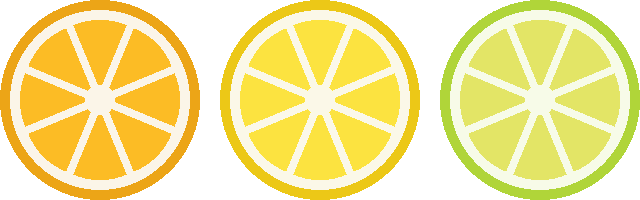

In [22]:
#teacher-only
from pytamaro import above, save_graphic

def arrangement(fruit_diameter: float) -> Graphic:
    return above(
        sliced_orange(fruit_diameter),
        beside(
            beside(
                sliced_lemon(fruit_diameter),
                rectangle(fruit_diameter / 10, 0, black)
            ),
            sliced_lime(fruit_diameter)
        )
    )

def horizontal_arrangement(fruit_diameter: float) -> Graphic:
    return beside(
        beside(
            sliced_orange(fruit_diameter),
            rectangle(fruit_diameter / 10, 0, black)
        ),
        beside(
            beside(
                sliced_lemon(fruit_diameter),
                rectangle(fruit_diameter / 10, 0, black)
            ),
            sliced_lime(fruit_diameter)
        )
    )

show_graphic(horizontal_arrangement(200))
save_graphic("sliced-citrus.svg", arrangement(200))